In [3]:
import os

project_folder = "House-Price-Prediction"
os.makedirs(project_folder, exist_ok=True)

print("House Price Project folder created!")

House Price Project folder created!


In [4]:
import os
os.makedirs("House-Price-Prediction/data", exist_ok=True)
os.makedirs("House-Price-Prediction/notebooks", exist_ok=True)
os.makedirs("House-Price-Prediction/src", exist_ok=True)
os.makedirs("House-Price-Prediction/models", exist_ok=True)
os.makedirs("House-Price-Prediction/app", exist_ok=True)

print("All folders created successfully!")

All folders created successfully!


In [6]:

readme = """# House Price Prediction

## Project Overview

This project predicts house prices using Machine Learning regression algorithms.

## Objective

To estimate house prices based on features such as living area, overall quality, year built, and other house attributes.

## Technologies Used

* Python
* Pandas
* NumPy
* Matplotlib
* Scikit-learn
* Google Colab
* Joblib

## Machine Learning Models

* Linear Regression
* Random Forest Regressor

## Project Steps

1. Data Collection
2. Data Loading
3. Data Cleaning
4. Exploratory Data Analysis
5. Feature Selection
6. Train-Test Split
7. Model Training
8. Model Evaluation
9. House Price Prediction
10. Model Saving

## Model Evaluation

The models are evaluated using:

* Mean Absolute Error (MAE)
* Root Mean Squared Error (RMSE)
* R2 Score
* Actual vs Predicted Price Visualization

## Dataset

The project uses the `house_prices_practice.csv` dataset.

The target column is `SalePrice`.

## How to Run

Install the required libraries:

```bash
pip install pandas numpy matplotlib scikit-learn joblib
```

Run the Python notebook in Google Colab.

Upload the dataset when prompted and execute the code.

## Project Structure

```text
house-price-prediction/
│
├── data/
│   └── house_prices_practice.csv
├── notebooks/
│   └── house_price_prediction.ipynb
├── models/
│   └── house_price_model.pkl
├── README.md
└── requirements.txt
```

## Results

The model performance is evaluated using MAE, RMSE, and R2 Score.

Add the actual evaluation scores after running the project.

## Conclusion

This project demonstrates an end-to-end Machine Learning workflow for House Price Prediction.

## Future Improvements

* Improve model performance using hyperparameter tuning.
* Try additional regression algorithms.
* Develop a web application using Flask or Streamlit.

## Author

Sandeep Krishna

## Disclaimer

This project is for educational purposes only.
Predicted prices are estimates and may not represent actual market prices.
"""

import os

project_folder = "House-Price-Prediction"

os.makedirs(project_folder, exist_ok=True)

with open(
    os.path.join(project_folder, "README.md"),
    "w",
    encoding="utf-8"
) as file:
    file.write(readme)

print("README.md created successfully!")
print("File location:", os.path.join(project_folder, "README.md"))


README.md created successfully!
File location: House-Price-Prediction/README.md


In [7]:
import os

os.makedirs("House-Price-Prediction/data/raw", exist_ok=True)
os.makedirs("House-Price-Prediction/data/processed", exist_ok=True)

print("Data folders created successfully!")

Data folders created successfully!


In [8]:
from google.colab import files
uploaded=files.upload()

Saving house_prices_practice.csv to house_prices_practice.csv


Libraries Import

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


LOADING THE DATASET

In [13]:
import pandas as pd

df=pd.read_csv("House-Price-Prediction/house_prices_practice.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (300, 10)


,Id,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,FullBath,BedroomAbvGr,LotArea,SalePrice
0,1,7,1560,0,1658,1969,2,1,8059,177106
1,2,4,2827,2,1319,2012,3,4,13530,301044
2,3,8,3920,0,841,2010,1,4,9010,360609
3,4,5,3044,0,1058,1998,0,4,13207,240556
4,5,7,801,1,2428,2020,0,1,9117,193656


— Data Understanding

In [14]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Column Names:
['Id', 'OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'YearBuilt', 'FullBath', 'BedroomAbvGr', 'LotArea', 'SalePrice']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Id            300 non-null    int64
 1   OverallQual   300 non-null    int64
 2   GrLivArea     300 non-null    int64
 3   GarageCars    300 non-null    int64
 4   TotalBsmtSF   300 non-null    int64
 5   YearBuilt     300 non-null    int64
 6   FullBath      300 non-null    int64
 7   BedroomAbvGr  300 non-null    int64
 8   LotArea       300 non-null    int64
 9   SalePrice     300 non-null    int64
dtypes: int64(10)
memory usage: 23.6 KB

Statistical Summary:


,Id,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,YearBuilt,FullBath,BedroomAbvGr,LotArea,SalePrice
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,150.500000,5.326667,2307.386667,1.330000,1468.796667,1986.163333,1.523333,2.926667,8969.453333,252262.903333
std,86.746758,2.873001,1042.561303,1.109898,672.333705,21.377089,1.131543,1.456604,3753.531132,74998.055214
min,1.000000,1.000000,504.000000,0.000000,303.000000,1950.000000,0.000000,1.000000,2009.000000,82494.000000
25%,75.750000,3.000000,1392.250000,0.000000,903.000000,1967.000000,0.000000,2.000000,5996.250000,190355.250000
50%,150.500000,5.000000,2265.500000,1.000000,1502.000000,1986.000000,2.000000,3.000000,9031.000000,251292.500000
75%,225.250000,8.000000,3306.500000,2.000000,2129.500000,2004.250000,3.000000,4.000000,12316.000000,307105.000000
max,300.000000,10.000000,3998.000000,3.000000,2492.000000,2023.000000,3.000000,5.000000,14987.000000,435291.000000



Missing Values:
Id              0
OverallQual     0
GrLivArea       0
GarageCars      0
TotalBsmtSF     0
YearBuilt       0
FullBath        0
BedroomAbvGr    0
LotArea         0
SalePrice       0
dtype: int64

Duplicate Rows: 0


Exploratory Data Analysis (EDA)

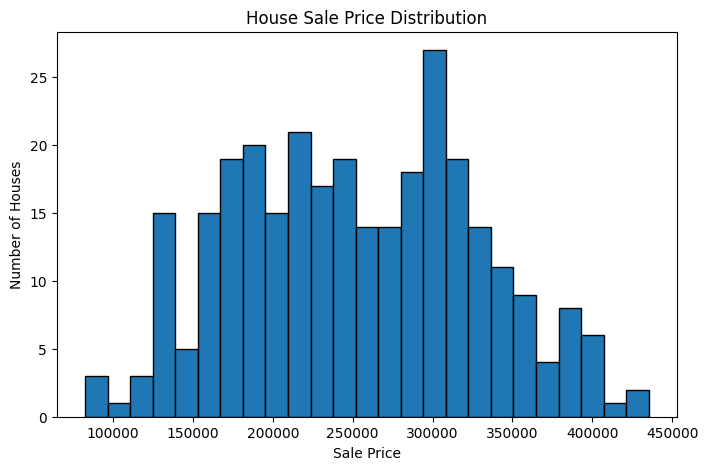

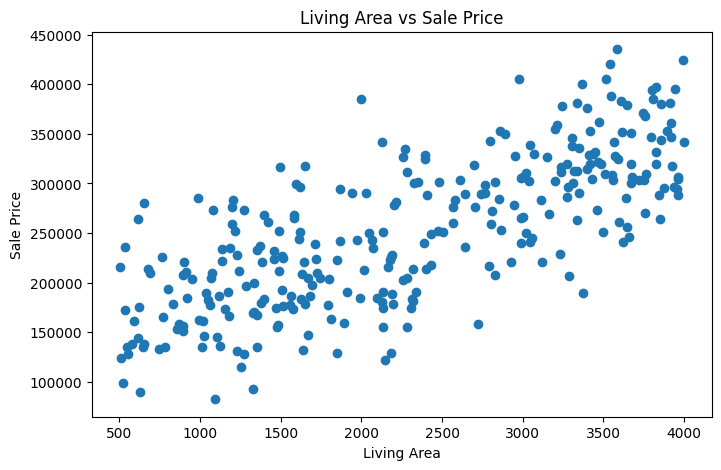

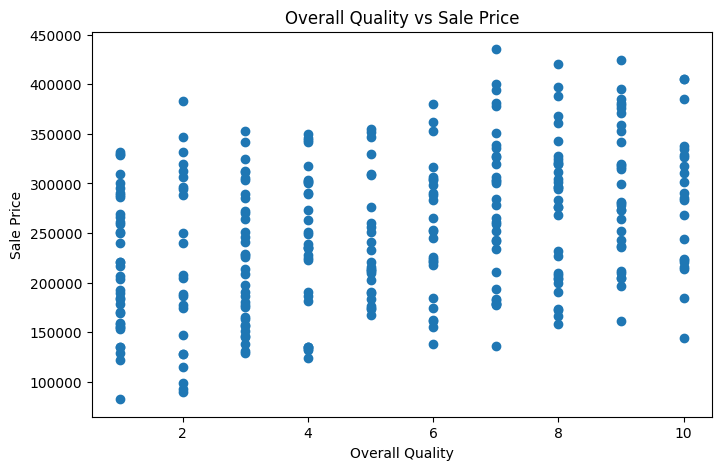

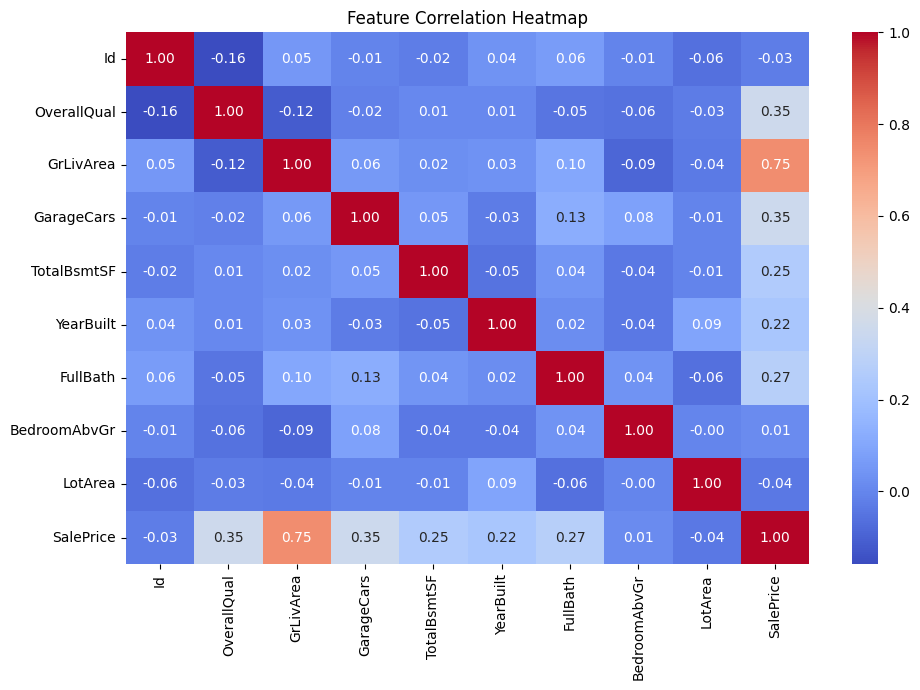

In [16]:
# Sale Price Distribution
plt.figure(figsize=(8, 5))
plt.hist(df["SalePrice"], bins=25, edgecolor="black")
plt.title("House Sale Price Distribution")
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")
plt.show()

# Living Area vs Sale Price
plt.figure(figsize=(8, 5))
plt.scatter(df["GrLivArea"], df["SalePrice"])
plt.title("Living Area vs Sale Price")
plt.xlabel("Living Area")
plt.ylabel("Sale Price")
plt.show()

# Overall Quality vs Sale Price
plt.figure(figsize=(8, 5))
plt.scatter(df["OverallQual"], df["SalePrice"])
plt.title("Overall Quality vs Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")
plt.show()

# Correlation Heatmap
import seaborn as sns
plt.figure(figsize=(10, 7))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

Features and Target

In [17]:
# Id is an identifier, so do not use it as a prediction feature
X = df.drop(columns=["SalePrice", "Id"])
y = df["SalePrice"]

print("Features:")
print(X.columns.tolist())

print("\nTarget: SalePrice")
print("X shape:", X.shape)
print("y shape:", y.shape)

Features:
['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'YearBuilt', 'FullBath', 'BedroomAbvGr', 'LotArea']

Target: SalePrice
X shape: (300, 8)
y shape: (300,)


Train-Test Split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 240
Testing rows: 60


Linear Regression Model

In [19]:
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

print("Linear Regression Results")
print("MAE:", mean_absolute_error(y_test, linear_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, linear_pred)))
print("R2 Score:", r2_score(y_test, linear_pred))

Linear Regression Results
MAE: 10431.655979708512
RMSE: 12505.459264618952
R2 Score: 0.9724369952260822


Random Forest Model

In [20]:
rf_model = Pipeline([
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Results")
print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2 Score:", r2_score(y_test, rf_pred))

Random Forest Results
MAE: 21414.515000000007
RMSE: 27405.669252765325
R2 Score: 0.8676243539162354


Compare Both Models

In [21]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, linear_pred),
        mean_absolute_error(y_test, rf_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, linear_pred)),
        np.sqrt(mean_squared_error(y_test, rf_pred))
    ],
    "R2 Score": [
        r2_score(y_test, linear_pred),
        r2_score(y_test, rf_pred)
    ]
})

display(results.round(2))

best_model_name = results.loc[
    results["R2 Score"].idxmax(), "Model"
]

print("Best model on this test split:", best_model_name)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,10431.66,12505.46,0.97
1,Random Forest,21414.52,27405.67,0.87


Best model on this test split: Linear Regression


Actual vs Predicted Graph

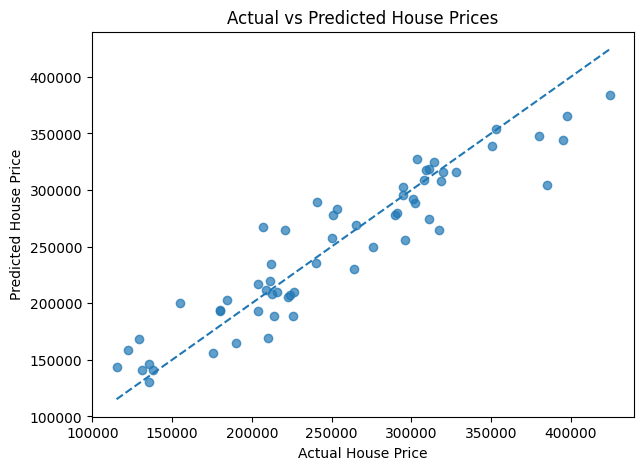

In [22]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, rf_pred, alpha=0.7)

min_value = min(y_test.min(), rf_pred.min())
max_value = max(y_test.max(), rf_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")
plt.show()

Predict a New House Price

In [23]:
# Example house details
new_house = pd.DataFrame([{
    "OverallQual": 7,
    "GrLivArea": 1800,
    "GarageCars": 2,
    "TotalBsmtSF": 1000,
    "YearBuilt": 2015,
    "FullBath": 2,
    "BedroomAbvGr": 3,
    "LotArea": 8500
}])

predicted_price = rf_model.predict(new_house)[0]

print("Predicted House Price:", round(predicted_price, 2))

Predicted House Price: 249682.6


Save the Trained Model

In [24]:
import joblib

joblib.dump(rf_model, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!
